*Think Linear Algebra* is not for sale yet, but if you would like to support this project, you can [buy me a coffee](https://buymeacoffee.com/allendowney).

# The Principal Components of Anthropometry

 the ANSUR-II dataset, which includes 93 measurements from a sample of U.S. military personnel

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/ThinkLinearAlgebra/blob/chapters/correlation.ipynb).

In [1]:
# Install empirical dist if we don't already have it

try:
    import empiricaldist
except ImportError:
    !pip install empiricaldist

In [2]:
# download utils.py

from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve
        local, _ = urlretrieve(url, filename)
        print('Downloaded ' + local)
        
download("https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/notebooks/utils.py")

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from utils import set_precision

set_precision(4)

## The data

Here's the ANSUR data, originally downloaded from [The OPEN Design Lab](https://www.openlab.psu.edu/ansur2/).

In [4]:
download("https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/data/ANSURIIFEMALEPublic.csv")
download("https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/data/ANSURIIMALEPublic.csv")

In [5]:
ansur_female = pd.read_csv("ANSURIIFEMALEPublic.csv", encoding="ISO-8859-1")
ansur_female.shape

(1986, 108)

In [6]:
ansur_male = pd.read_csv("ANSURIIMALEPublic.csv", encoding="ISO-8859-1")
ansur_male.shape

(4082, 108)

Since heights are in mm, I converted to cm.

In [7]:
height_male = ansur_male["stature"] / 10
height_female = ansur_female["stature"] / 10

In [8]:
def add_earratio(df):
    df['earratio'] = df['earprotrusion'] / df['earbreadth']

In [9]:
measurements = [column for column in ansur_female.columns if column.lower() == column]
measurements

['abdominalextensiondepthsitting',
 'acromialheight',
 'acromionradialelength',
 'anklecircumference',
 'axillaheight',
 'balloffootcircumference',
 'balloffootlength',
 'biacromialbreadth',
 'bicepscircumferenceflexed',
 'bicristalbreadth',
 'bideltoidbreadth',
 'bimalleolarbreadth',
 'bitragionchinarc',
 'bitragionsubmandibulararc',
 'bizygomaticbreadth',
 'buttockcircumference',
 'buttockdepth',
 'buttockheight',
 'buttockkneelength',
 'buttockpopliteallength',
 'calfcircumference',
 'cervicaleheight',
 'chestbreadth',
 'chestcircumference',
 'chestdepth',
 'chestheight',
 'crotchheight',
 'crotchlengthomphalion',
 'crotchlengthposterioromphalion',
 'earbreadth',
 'earlength',
 'earprotrusion',
 'elbowrestheight',
 'eyeheightsitting',
 'footbreadthhorizontal',
 'footlength',
 'forearmcenterofgriplength',
 'forearmcircumferenceflexed',
 'forearmforearmbreadth',
 'forearmhandlength',
 'functionalleglength',
 'handbreadth',
 'handcircumference',
 'handlength',
 'headbreadth',
 'headcir

In [10]:
len(measurements)

93

In [11]:
ansur_male[measurements]

,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,bicristalbreadth,...,verticaltrunkcircumferenceusa,waistbacklength,waistbreadth,waistcircumference,waistdepth,waistfrontlengthsitting,waistheightomphalion,weightkg,wristcircumference,wristheight
0,266,1467,337,222,1347,253,202,401,369,274,...,1700,501,329,933,240,440,1054,815,175,853
1,233,1395,326,220,1293,245,193,394,338,257,...,1627,432,316,870,225,371,1054,726,167,815
2,287,1430,341,230,1327,256,196,427,408,261,...,1678,472,329,964,255,411,1041,929,180,831
3,234,1347,310,230,1239,262,199,401,359,262,...,1625,461,315,857,205,399,968,794,176,793
4,250,1585,372,247,1478,267,224,435,356,263,...,1679,467,303,868,214,379,1245,946,188,954
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4077,235,1353,312,216,1263,228,193,384,318,241,...,1557,442,279,816,210,347,1016,675,163,778
4078,247,1473,336,234,1346,253,196,428,374,284,...,1715,475,351,978,235,385,1082,896,178,873
4079,264,1394,313,227,1280,245,193,407,367,271,...,1682,483,333,991,258,353,1011,832,178,822
4080,203,1417,327,223,1314,250,196,419,365,271,...,1589,430,293,783,192,350,1062,731,172,837


In [12]:
df = ansur_male[measurements]

## Principle Component Analysis


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# In this example, we will first standardize the data and then perform PCA.

# Step 3.1: Create a StandardScaler step
scaler = StandardScaler()

# Step 3.2: Create a PCA step
pca = PCA(n_components=10) 

# Step 4: Create the pipeline
steps = [
    ('scaler', scaler),  # Standardize the data
    ('pca', pca)        # Perform PCA
]

pipeline = Pipeline(steps)

# Fit the pipeline to your data
pipeline.fit(df)

# Now, you can access the transformed data and principal components if needed.
transformed_data = pipeline.transform(df)  # Transformed data after PCA
principal_components = pca.components_    # Principal components (eigenvectors)

# You can also access the explained variance ratio to see how much variance is explained by each component.
explained_variance_ratio = pca.explained_variance_ratio_
explained_variance_ratio

array([0.44234507, 0.1749688 , 0.04206542, 0.0324817 , 0.02284768,
       0.02117414, 0.01887397, 0.01487041, 0.01424227, 0.01333891])

Here's a visualization of explained variance versus number of components.
I lifted this from [The Python Data Science Handbook](https://jakevdp.github.io/PythonDataScienceHandbook/05.09-principal-component-analysis.html).

In [14]:
ys = np.cumsum(pca.explained_variance_ratio_)
xs = np.arange(len(ys)) + 1
ys

array([0.44234507, 0.61731386, 0.65937928, 0.69186098, 0.71470867,
       0.7358828 , 0.75475678, 0.76962718, 0.78386945, 0.79720836])

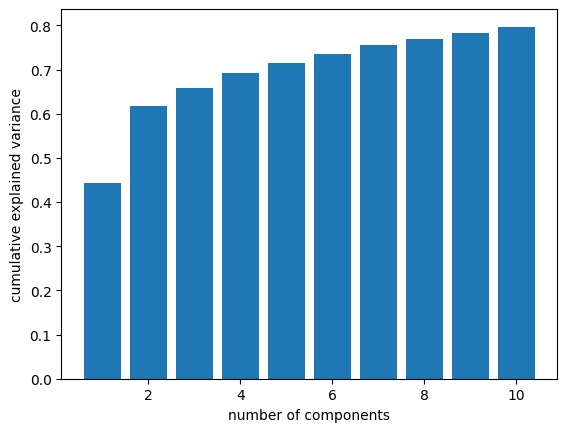

In [15]:
plt.bar(xs, ys)
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')

plt.savefig('ansur_pca1.png', dpi=300)

With one component, we can capture 44% of the variation in the measurements.
With two components, we're up to 62%.
After that, the gains are smaller (as we expect), but with 10 measurements, we get up to 78%.

## Loadings

Looking at the loadings, we can see which measurements contribute the most to each of the components, so we can get a sense of which characteristics each component captures. 

In [16]:
loadings = pca.components_  # Get the loadings (eigenvectors)

# Create a DataFrame to store the loadings with feature names as columns
loadings_df = pd.DataFrame(loadings, columns=measurements)
loadings_df

,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,bicristalbreadth,...,verticaltrunkcircumferenceusa,waistbacklength,waistbreadth,waistcircumference,waistdepth,waistfrontlengthsitting,waistheightomphalion,weightkg,wristcircumference,wristheight
0,0.085451,0.134108,0.116021,0.100365,0.127055,0.105897,0.112045,0.108305,0.092030,0.103360,...,0.124746,0.094822,0.097267,0.095846,0.087184,0.082944,0.114016,0.131211,0.115607,0.120198
1,0.162882,-0.099494,-0.106095,0.092119,-0.123047,0.037801,-0.064844,0.017398,0.141551,0.055853,...,0.096331,0.038278,0.157748,0.165992,0.161084,0.061621,-0.150431,0.126668,0.062109,-0.048192
2,0.014396,0.122854,-0.012458,-0.022597,0.112583,-0.073203,-0.118899,-0.059997,-0.103355,0.135301,...,0.167963,0.179761,0.081045,0.045143,0.021002,0.228020,0.030051,0.003645,-0.042589,0.216035
3,-0.173876,-0.015045,-0.085686,0.166717,-0.009381,0.246993,0.099335,0.044503,-0.032581,-0.021541,...,0.000876,-0.023759,-0.131962,-0.161452,-0.181389,0.043228,-0.010536,-0.055894,0.153330,0.019576
4,-0.067122,-0.015899,0.052816,-0.179243,-0.008870,-0.148962,-0.102523,0.291565,-0.025614,-0.022255,...,-0.014777,-0.006210,-0.053418,-0.058214,-0.067672,0.048683,0.011551,-0.044015,-0.064763,-0.057597
5,0.068259,0.045160,0.009190,-0.079737,0.034701,-0.068621,-0.007759,-0.210369,-0.060019,0.028891,...,0.014755,0.083360,0.029061,0.049992,0.071115,0.006987,-0.017592,0.003705,-0.105686,0.075267
6,-0.093476,-0.012387,-0.032037,0.108992,0.004803,-0.023543,-0.038956,0.041419,0.045023,-0.026664,...,-0.018318,-0.284220,-0.027533,-0.069905,-0.116681,-0.202276,0.123818,0.022759,-0.095696,-0.009274
7,0.052361,-0.061787,0.114918,0.010139,-0.048472,0.003087,-0.084960,0.011853,-0.096510,-0.023072,...,0.008929,-0.043860,0.064721,0.051647,0.029223,0.142583,-0.057864,-0.006743,-0.019706,-0.200217
8,-0.003623,-0.041775,0.010452,0.128650,-0.038322,0.076571,0.143718,0.113202,-0.131494,0.252774,...,-0.065818,0.182729,0.108615,0.052146,0.018826,-0.060424,-0.048807,0.006111,-0.105465,-0.049518
9,-0.083986,0.014356,-0.070832,0.042657,0.003944,0.106749,-0.032232,-0.001546,0.007314,0.077170,...,-0.054163,-0.228431,-0.019825,-0.070181,-0.093979,-0.267772,0.129029,-0.027907,0.010906,0.088248


In [17]:
loadings_transposed = loadings_df.transpose()
loadings_transposed

,0,1,2,3,4,5,6,7,8,9
abdominalextensiondepthsitting,0.085451,0.162882,0.014396,-0.173876,-0.067122,0.068259,-0.093476,0.052361,-0.003623,-0.083986
acromialheight,0.134108,-0.099494,0.122854,-0.015045,-0.015899,0.045160,-0.012387,-0.061787,-0.041775,0.014356
acromionradialelength,0.116021,-0.106095,-0.012458,-0.085686,0.052816,0.009190,-0.032037,0.114918,0.010452,-0.070832
anklecircumference,0.100365,0.092119,-0.022597,0.166717,-0.179243,-0.079737,0.108992,0.010139,0.128650,0.042657
axillaheight,0.127055,-0.123047,0.112583,-0.009381,-0.008870,0.034701,0.004803,-0.048472,-0.038322,0.003944
...,...,...,...,...,...,...,...,...,...,...
waistfrontlengthsitting,0.082944,0.061621,0.228020,0.043228,0.048683,0.006987,-0.202276,0.142583,-0.060424,-0.267772
waistheightomphalion,0.114016,-0.150431,0.030051,-0.010536,0.011551,-0.017592,0.123818,-0.057864,-0.048807,0.129029
weightkg,0.131211,0.126668,0.003645,-0.055894,-0.044015,0.003705,0.022759,-0.006743,0.006111,-0.027907
wristcircumference,0.115607,0.062109,-0.042589,0.153330,-0.064763,-0.105686,-0.095696,-0.019706,-0.105465,0.010906


In [18]:
num_top_features = 5

# Iterate through each principal component
for i, col in loadings_transposed.items():
    print(f"Principal Component {i+1}:")
    
    # Sort the features by absolute loading values for the current principal component
    sorted_features = col.sort_values(key=abs, ascending=False)
    
    # Select the top N features with the highest absolute loadings
    top_features = sorted_features[:num_top_features].round(3)
    
    # Print the top correlated factors for the current principal component
    for name, val in top_features.items():
        print(-val, '\t', name)
    print()

Principal Component 1:
-0.135 	 suprasternaleheight
-0.134 	 cervicaleheight
-0.134 	 buttockkneelength
-0.134 	 acromialheight
-0.133 	 kneeheightsitting

Principal Component 2:
-0.166 	 waistcircumference
0.163 	 poplitealheight
-0.163 	 abdominalextensiondepthsitting
-0.161 	 waistdepth
-0.159 	 buttockdepth

Principal Component 3:
-0.338 	 elbowrestheight
-0.31 	 eyeheightsitting
-0.307 	 sittingheight
-0.228 	 waistfrontlengthsitting
0.225 	 heelbreadth

Principal Component 4:
-0.247 	 balloffootcircumference
-0.232 	 bimalleolarbreadth
-0.22 	 footbreadthhorizontal
-0.218 	 handbreadth
-0.212 	 sittingheight

Principal Component 5:
-0.319 	 interscyeii
-0.292 	 biacromialbreadth
-0.275 	 shoulderlength
-0.273 	 interscyei
-0.184 	 shouldercircumference

Principal Component 6:
-0.34 	 headcircumference
-0.321 	 headbreadth
0.317 	 shoulderlength
-0.278 	 tragiontopofhead
-0.262 	 interpupillarybreadth

Principal Component 7:
-0.374 	 crotchlengthposterioromphalion
0.321 	 earbread

I won't explain all of the measurements, but if there are any you are curious about, you can look them up in [*The Measurer’s Handbook*](http://tools.openlab.psu.edu/publicData/ANSURII-TR11-017.pdf) which includes details on "sampling strategy and measuring techniques" as well as descriptions and diagrams of the landmarks and measurements between them.

* Not surprisingly, the first component is loaded with measurements of height. If you want to predict someone's measurements, and can only use one number, choose height.

* The second component is loaded with measurements of girth. Again, no surprises so far.

* The third component seems to capture torso length. And that makes sense, too. One you know how tall someone is, it helps to know how that height is split between torso and legs.

* The fourth component seems to capture hand and foot size (with sitting height thrown in just to remind us that PCA is not obligated to find components that align perfectly with the axes we expect).

* Component 5 is all about the shoulders.

* Component 6 is all about the head.

After that, things are not so neat. But two things are worth noting:

* Component 7 is mostly related to the dimensions of the pelvis, but...

* Components 7, 8, and 10 are surprisingly loaded up with ear measurements.

As we saw in the previous article, there seems to be something special about ears.
Once you have exhausted the information carried by the most obvious measurements, the dimensions of the ear seem to be strangely salient.

## Singular Value Decomposition

In [ ]:
# --- PCA via SVD (correlation PCA: center & scale first) ---

# 1) Standardize each column (match StandardScaler: ddof=0)
mu = df.mean(axis=0)
sigma = df.std(axis=0, ddof=0)
X_std = (df - mu) / sigma
X_std = X_std.to_numpy()  # (n, p)

n, p = X_std.shape
n_components = 10  # match your sklearn PCA(n_components=10)

# 2) SVD of standardized matrix
#    X_std = U @ diag(S) @ Vt
U, S, Vt = np.linalg.svd(X_std, full_matrices=False)

array([409.78736905, 257.72602478, 126.36901345, 111.04457675,
        93.13202783,  89.65630761,  84.64662141,  75.13450184,
        73.53050275,  71.16036607,  68.65341179,  66.40006972,
        59.48754046,  59.17034854,  58.16201119,  56.34775619,
        54.92695496,  52.50790793,  51.61768803,  50.05252975,
        48.77964389,  47.44194247,  46.61470847,  45.38824785,
        44.57334567,  43.17420817,  41.58595614,  40.05586987,
        39.06275292,  37.2300236 ,  36.27608944,  34.97166962,
        34.19298905,  32.6148265 ,  32.31266765,  30.83646169,
        30.28542116,  29.7416459 ,  28.79024126,  28.00218241,
        27.48132768,  26.75519186,  25.93926213,  25.16918297,
        24.71553217,  24.40199281,  23.83153965,  23.46788372,
        23.27095686,  22.87401883,  21.6337858 ,  21.14227237,
        20.63564572,  20.14459445,  19.49108647,  19.22927146,
        18.38823105,  17.73365911,  17.65588696,  17.02681369,
        16.20625556,  16.11919326,  15.53780872,  15.35

In [20]:
# 3) PCA quantities
# Components / loadings (each row is a PC direction in feature space)
components = Vt[:n_components, :]                 # shape (k, p)

# Scores (transformed data): either U*S or X_std @ V
scores = U[:, :n_components] * S[:n_components]   # shape (n, k)

# Explained variance (eigenvalues of correlation matrix)
explained_variance = (S**2) / (n - 1)             # length p (since full_matrices=False, len(S)=min(n,p))
explained_variance = explained_variance[:n_components]

# Explained variance ratio
total_var = (S**2).sum() / (n - 1)
explained_variance_ratio = explained_variance / total_var

# For parity with sklearn names:
transformed_data = scores
principal_components = components

# Quick check of shapes
print("scores:", scores.shape, "components:", components.shape)
print("explained_variance_ratio[:5]:", explained_variance_ratio[:5])

scores: (4082, 10) components: (10, 93)
explained_variance_ratio[:5]: [0.44234507 0.1749688  0.04206542 0.0324817  0.02284768]


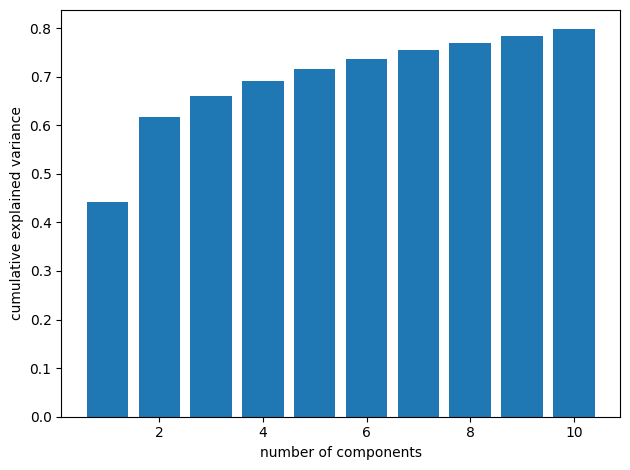

In [21]:
# --- Cumulative explained variance plot (like your existing code) ---
ys = np.cumsum(explained_variance_ratio)
xs = np.arange(1, len(ys) + 1)

plt.bar(xs, ys)
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.tight_layout()
plt.savefig('ansur_pca_svd_cumvar.png', dpi=300)

In [22]:
# --- Loadings DataFrame (same structure you had) ---
loadings_df = pd.DataFrame(principal_components, columns=measurements)
loadings_transposed = loadings_df.transpose()
loadings_df  # display if in a notebook

,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,bicristalbreadth,...,verticaltrunkcircumferenceusa,waistbacklength,waistbreadth,waistcircumference,waistdepth,waistfrontlengthsitting,waistheightomphalion,weightkg,wristcircumference,wristheight
0,-0.085451,-0.134108,-0.116021,-0.100365,-0.127055,-0.105897,-0.112045,-0.108305,-0.092030,-0.103360,...,-0.124746,-0.094822,-0.097267,-0.095846,-0.087184,-0.082944,-0.114016,-0.131211,-0.115607,-0.120198
1,0.162882,-0.099494,-0.106095,0.092119,-0.123047,0.037801,-0.064844,0.017398,0.141551,0.055853,...,0.096331,0.038278,0.157748,0.165992,0.161084,0.061621,-0.150431,0.126668,0.062109,-0.048192
2,0.014396,0.122854,-0.012458,-0.022597,0.112583,-0.073203,-0.118899,-0.059997,-0.103355,0.135301,...,0.167963,0.179761,0.081045,0.045143,0.021002,0.228020,0.030051,0.003645,-0.042589,0.216035
3,0.173876,0.015045,0.085686,-0.166717,0.009381,-0.246993,-0.099335,-0.044503,0.032581,0.021541,...,-0.000876,0.023759,0.131962,0.161452,0.181389,-0.043228,0.010536,0.055894,-0.153330,-0.019576
4,-0.067122,-0.015899,0.052816,-0.179243,-0.008870,-0.148962,-0.102523,0.291565,-0.025614,-0.022255,...,-0.014777,-0.006210,-0.053418,-0.058214,-0.067672,0.048683,0.011551,-0.044015,-0.064763,-0.057597
5,0.068259,0.045160,0.009190,-0.079737,0.034701,-0.068621,-0.007759,-0.210369,-0.060019,0.028891,...,0.014755,0.083360,0.029061,0.049992,0.071115,0.006987,-0.017592,0.003705,-0.105686,0.075267
6,-0.093476,-0.012387,-0.032037,0.108992,0.004803,-0.023543,-0.038956,0.041419,0.045023,-0.026664,...,-0.018318,-0.284220,-0.027533,-0.069905,-0.116681,-0.202276,0.123818,0.022759,-0.095696,-0.009274
7,0.052361,-0.061787,0.114918,0.010139,-0.048472,0.003087,-0.084960,0.011853,-0.096510,-0.023072,...,0.008929,-0.043860,0.064721,0.051647,0.029223,0.142583,-0.057864,-0.006743,-0.019706,-0.200217
8,-0.003623,-0.041775,0.010452,0.128650,-0.038322,0.076571,0.143718,0.113202,-0.131494,0.252774,...,-0.065818,0.182729,0.108615,0.052146,0.018826,-0.060424,-0.048807,0.006111,-0.105465,-0.049518
9,0.083986,-0.014356,0.070832,-0.042657,-0.003944,-0.106749,0.032232,0.001546,-0.007314,-0.077170,...,0.054163,0.228431,0.019825,0.070181,0.093979,0.267772,-0.129029,0.027907,-0.010906,-0.088248


In [23]:
# --- Print top loadings per component (by absolute value) ---
num_top_features = 5
for i, col in loadings_transposed.items():
    print(f"\nPrincipal Component {i+1}:")
    top_features = col.reindex(col.abs().sort_values(ascending=False).index)[:num_top_features].round(3)
    for name, val in top_features.items():
        print(f"{val:+.3f}\t{name}")


Principal Component 1:
-0.135	suprasternaleheight
-0.134	cervicaleheight
-0.134	buttockkneelength
-0.134	acromialheight
-0.133	kneeheightsitting

Principal Component 2:
+0.166	waistcircumference
-0.163	poplitealheight
+0.163	abdominalextensiondepthsitting
+0.161	waistdepth
+0.159	buttockdepth

Principal Component 3:
+0.338	elbowrestheight
+0.310	eyeheightsitting
+0.307	sittingheight
+0.228	waistfrontlengthsitting
-0.225	heelbreadth

Principal Component 4:
-0.247	balloffootcircumference
-0.232	bimalleolarbreadth
-0.220	footbreadthhorizontal
-0.218	handbreadth
-0.212	sittingheight

Principal Component 5:
+0.319	interscyeii
+0.292	biacromialbreadth
+0.275	shoulderlength
+0.273	interscyei
+0.184	shouldercircumference

Principal Component 6:
+0.340	headcircumference
+0.321	headbreadth
-0.317	shoulderlength
+0.278	tragiontopofhead
+0.262	interpupillarybreadth

Principal Component 7:
+0.374	crotchlengthposterioromphalion
-0.321	earbreadth
-0.299	earlength
-0.284	waistbacklength
+0.253	crotch

[Think Linear Algebra](https://allendowney.github.io/ThinkLinearAlgebra/index.html)

Copyright 2025 [Allen B. Downey](https://allendowney.com)

Code license: [MIT License](https://mit-license.org/)

Text license: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)